In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

DOSSIER_DONNEES = Path("Data nettoyees")
CHEMIN_PRIVE = DOSSIER_DONNEES / "DS_DERA_PRIVE_SERIES_LONGUES_data_nettoye.csv"

if not CHEMIN_PRIVE.is_file():
    raise FileNotFoundError("Fichier privé nettoyé introuvable.")

prive = pd.read_csv(CHEMIN_PRIVE, sep=";", encoding="utf-8-sig")


In [ ]:
SALAIRE = 'Salaire net moyen mensuel (Euros constants)'
MOYENNE = 'Ensemble'
P10 = '10e centile (D1 - 10% gagnent moins)'
P25 = '1er quartile (Q1 - 25% gagnent moins)'
P50 = 'Médiane (50% gagnent moins/plus)'
P90 = '90e centile (D9 - 10% gagnent plus)'
P75 = '3e quartile (Q3 - 75% gagnent moins)'

VALEURS_ENSEMBLE = {
    'secteur_activite': 'Ensemble des secteurs',
    'tranche_age': 'Ensemble',
    'taille_entreprise': 'Ensemble',
    'categorie_socio_prof': 'Ensemble',
    'sexe': 'Ensemble',
    'temps_travail': 'Ensemble',
}

def garder_ensemble_des_autres_dimensions(df, dimension=None):
    for colonne, modalite in VALEURS_ENSEMBLE.items():
        if colonne in df.columns and colonne != dimension:
            df = df[df[colonne] == modalite]
    return df

def extraire_salaire(df, quantiles, dimension=None):
    resultat = garder_ensemble_des_autres_dimensions(df, dimension)
    resultat = resultat[
        (resultat['indicateur'] == SALAIRE)
        & (resultat['unite'] == 'Euros constants')
        & (resultat['centile_salaire'].isin(quantiles))
    ]

    cles = ['annee', 'centile_salaire']
    if dimension:
        cles = [dimension] + cles

    if resultat.duplicated(cles).any():
        raise ValueError(f'Plusieurs valeurs pour les mêmes clés : {cles}')

    return resultat

def serie_quantile(df, quantile, etiquette):
    resultat = extraire_salaire(df, [quantile])
    return resultat[['annee', 'valeur']].rename(
        columns={'valeur': 'Salaire (€ constants)'}
    ).assign(Série=etiquette)

def calculer_ecarts_par_categorie(table, categorie):
    salaires = table.pivot(
        index=['annee', categorie], columns='sexe', values='valeur'
    ).dropna(subset=['Homme', 'Femme'])

    ecart = 100 * (salaires['Homme'] - salaires['Femme']) / salaires['Homme']
    return ecart.unstack(categorie)


# Statistiques descriptives

On explore uniquement les données du secteur privé : salaires par secteur, sexe, taille d’entreprise et temps de travail, puis quelques indicateurs d’inégalités et leur évolution.

## 1. Écart de salaire moyen entre hommes et femmes

Regardons d'abord l'écart de salaire moyen entre hommes et femmes **(salaire homme − salaire femme) / salaire homme × 100**. (en gardant le secteur, l’âge, la taille d’entreprise, la catégorie socio-professionnelle et le temps de travail sur « Ensemble ».)

Entre 1996 et 2024, l’écart de salaire net moyen mensuel (en euros constants) entre hommes et femmes dans le privé a nettement baissé, passant de 22,3 % à 13,0 %.
 Cette baisse s’est accélérée depuis 2015 (-5,0 points en neuf ans), avec la hausse du salaire moyen féminin (+6,2 %) et une quasi-stagnation de celui des hommes (+0,2 %). 
 
 L’écart reste toutefois important en 2024 (377 € net par mois) et, comme il s’agit de moyennes agrégées, il doit être affiné par secteur et par CSP.


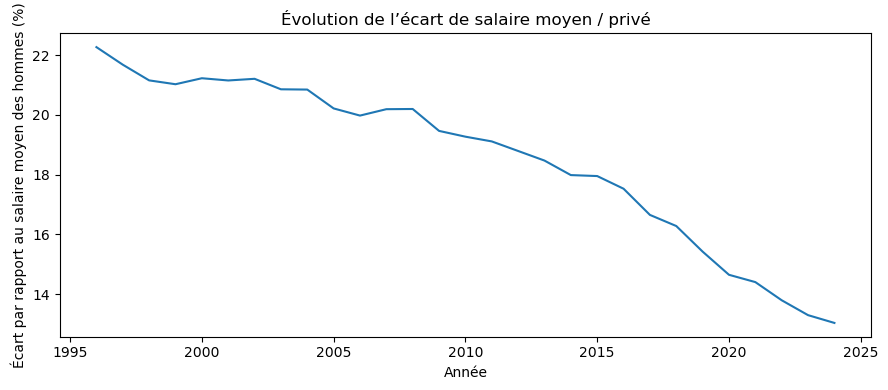

In [ ]:
salaires_sexe = extraire_salaire(prive, [MOYENNE], 'sexe')

moyenne_sexe = salaires_sexe.pivot(
    index='annee', columns='sexe', values='valeur'
).dropna()

moyenne_sexe['Écart H-F (% du salaire homme)'] = (
    100 * (moyenne_sexe['Homme'] - moyenne_sexe['Femme']) / moyenne_sexe['Homme']
)

moyenne_sexe['Écart H-F (% du salaire homme)'].plot(figsize=(9, 4))
plt.title('Évolution de l’écart de salaire moyen / privé')
plt.xlabel('Année')
plt.ylabel('Écart par rapport au salaire moyen des hommes (%)')
plt.tight_layout()
plt.show()


## 3. Évolution de l’écart salarial par grande catégorie

### a. Secteurs
ici, on reprend le même écart **(SMH - SMF)/SMH × 100**, mais en regroupant les secteurs. On fait la moyenne simple des salaires moyens des secteurs qui la composent (nous n'avons pas de pondération donc c'est à nuancer). 

| Catégorie | Secteurs inclus | Fréquence cumulée |
|---|---|---:|
| Industrie et Énergie | Industries extractives/énergie/eau/déchets; alimentation/boissons/tabac; cokéfaction-raffinage; produits informatiques/électroniques/machines; matériels de transport; autres industries manufacturières | 1 548 |
| Construction | Construction | 258 |
| Services marchands | Commerce; transports; hébergement-restauration; information-communication; finance-assurance; immobilier; services aux entreprises (M_N) | 1 806 |
| Services non marchands et aux ménages | Administration publique/enseignement/santé/action sociale; arts, loisirs et autres services | 516 |

Les autres dimensions (âge, taille, catégorie socio-professionnelle et temps de travail) restent sur « Ensemble ».

On remarque que l’écart salarial recule dans toutes les grandes catégories entre 1996 et 2024, avec la plus forte baisse dans l’Industrie et Énergie (de 21,0 % à 9,1 %). 

On remarque également que depuis 2015,  l'écart pour la construction était négatif. Cela peut s'expliquer car les hommes occupent majoritairement les postes d'ouvriers de chantier, moins bien rémunérés, tandis que les femmes sont proportionnellement plus présentes dans les fonctions administratives. 

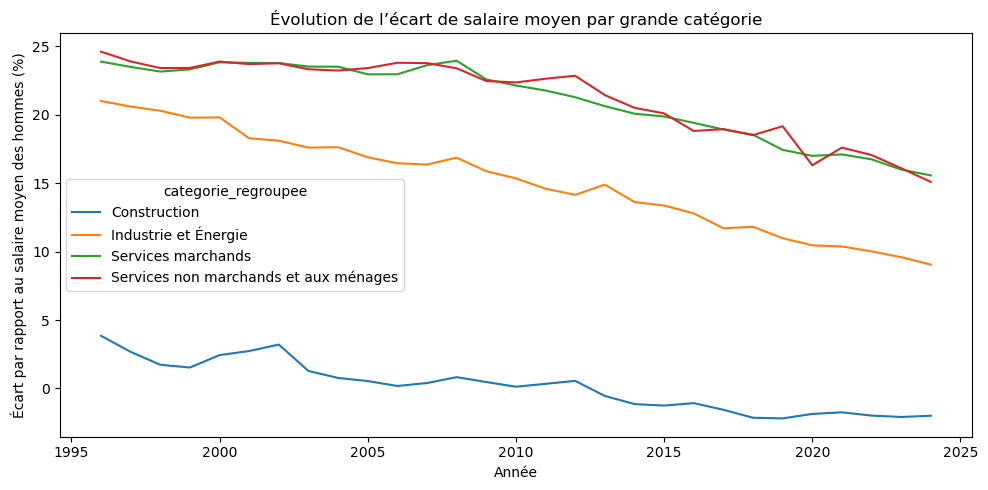

In [ ]:
CATEGORIES_SECTEURS = {
    'Industrie et Énergie': [
        'Industries extractives, énergie, eau, déchets (B_D_E)',
        'Fabrication d’aliments, boissons et tabac (C10T12)',
        'Cokéfaction et raffinage (C19)',
        'Fabrication de produits informatiques, électroniques et machines (C26T28)',
        'Fabrication de matériels de transport (C29_30)',
        'Autres industries manufacturières (C_OTH)',
    ],
    'Construction': ['Construction'],
    'Services marchands': [
        'Commerce ; réparation d’automobiles et de motocycles',
        'Transports et entreposage',
        'Hébergement et restauration',
        'Information et communication',
        'Activités financières et d’assurance',
        'Activités immobilières',
        'Activités spécialisées, scientifiques, techniques et services support (M_N)',
    ],
    'Services non marchands et aux ménages': [
        'Administration publique, enseignement, santé et action sociale (OTQ)',
        'Arts, divertissement, loisirs et autres services (R_S)',
    ],
}

secteur_vers_categorie = {
    secteur: categorie
    for categorie, secteurs in CATEGORIES_SECTEURS.items()
    for secteur in secteurs
}

secteurs_manquants = set(secteur_vers_categorie) - set(prive['secteur_activite'].dropna())
if secteurs_manquants:
    raise ValueError(f'Secteurs absents des données : {sorted(secteurs_manquants)}')

salaires_secteurs = prive[
    (prive['indicateur'] == SALAIRE)
    & (prive['unite'] == 'Euros constants')
    & (prive['centile_salaire'] == MOYENNE)
    & (prive['secteur_activite'].isin(secteur_vers_categorie))
    & (prive['sexe'].isin(['Homme', 'Femme']))
    & (prive['tranche_age'] == 'Ensemble')
    & (prive['taille_entreprise'] == 'Ensemble')
    & (prive['categorie_socio_prof'] == 'Ensemble')
    & (prive['temps_travail'] == 'Ensemble')
].copy()

salaires_secteurs['categorie_regroupee'] = salaires_secteurs['secteur_activite'].map(secteur_vers_categorie)

salaires_categories = (
    salaires_secteurs.groupby(['annee', 'categorie_regroupee', 'sexe'])['valeur']
    .mean()
    .reset_index()
)

ecarts_categories = calculer_ecarts_par_categorie(salaires_categories, 'categorie_regroupee')

ecarts_categories.plot(figsize=(10, 5))
plt.title('Évolution de l’écart de salaire moyen par grande catégorie')
plt.xlabel('Année')
plt.ylabel('Écart par rapport au salaire moyen des hommes (%)')
plt.tight_layout()
plt.show()


### b. catégorie socioprofessionnelle

On reutilise le même écart, mais cette fois pour les CSP. (En gardant le secteur, l’âge, la taille d’entreprise et le temps de travail sur « Ensemble »)

L’écart salarial diminue dans toutes les catégories socioprofessionnelles entre 1996 et 2024, avec la plus forte baisse chez les cadres (de 27,3 % à 14,7 %). Ils conservent tout de même l’écart le plus élevé en 2024, devant les ouvriers (12,5 %) et les professions intermédiaires (11,6 %). À l’inverse, les employés affichent l’écart le plus faible, qui s’est réduit (3,4 % en 2024 contre 11,5 % en 1996).

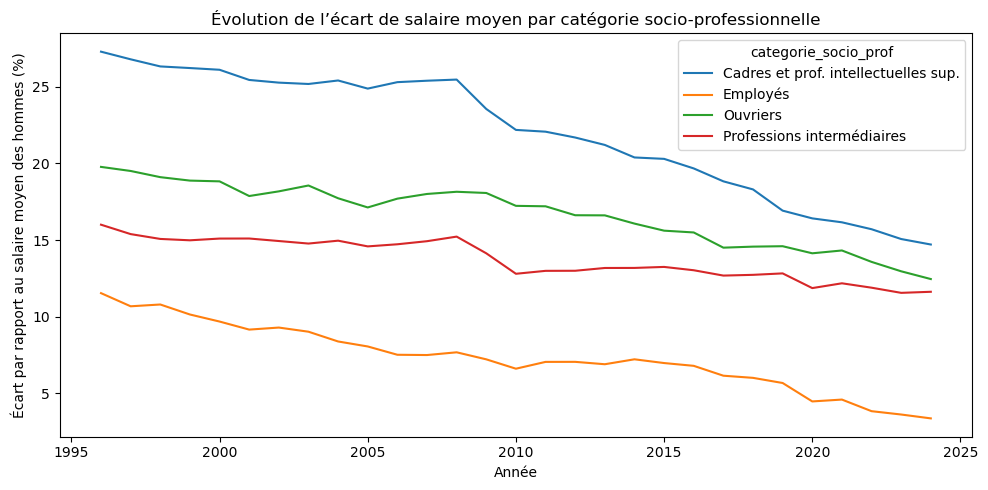

In [ ]:
salaires_socioprof = prive[
    (prive['indicateur'] == SALAIRE)
    & (prive['unite'] == 'Euros constants')
    & (prive['centile_salaire'] == MOYENNE)
    & (prive['secteur_activite'] == 'Ensemble des secteurs')
    & (prive['tranche_age'] == 'Ensemble')
    & (prive['taille_entreprise'] == 'Ensemble')
    & (prive['temps_travail'] == 'Ensemble')
    & (prive['categorie_socio_prof'] != 'Ensemble')
    & (prive['sexe'].isin(['Homme', 'Femme']))
].copy()

ecarts_socioprof = calculer_ecarts_par_categorie(salaires_socioprof, 'categorie_socio_prof')

categories_attendues = {
    'Cadres et prof. intellectuelles sup.',
    'Professions intermédiaires',
    'Employés',
    'Ouvriers',
}

if set(ecarts_socioprof.columns) != categories_attendues:
    raise ValueError(f'Catégories absentes : {sorted(categories_attendues - set(ecarts_socioprof.columns))}')

ecarts_socioprof.plot(figsize=(10, 5))
plt.title('Évolution de l’écart de salaire moyen par catégorie socio-professionnelle')
plt.xlabel('Année')
plt.ylabel('Écart par rapport au salaire moyen des hommes (%)')
plt.tight_layout()
plt.show()


## 4. Ratio P90/P10 selon le sexe
Nous utilisons le ratio **P90/P10**, où PX représente le X-ième centile afin de rendre compte de la dispersion des salaires. Plus il est élevé, plus les écarts sont importants. 

En 2024, il atteint 3,07 chez les hommes et 2,65 chez les femmes : les salaires sont donc plus dispersés chez les hommes. Le ratio a connu un pic en 2020, à 3,24 pour les hommes et 2,77 pour les femmes, avant de diminuer jusqu’en 2024. Les inégalités internes ont toutefois tendance à augmenter chez les femmes depuis 1996. 

On ajoute aussi l'évolution des salaires par Quantiles . l’ensemble des niveaux de salaire (du P10 au P90) progresse en euros constants, mais la hausse est nettement plus marquée en haut de la distribution (P90 et P75) qu’en bas (P10 et P25), ce qui creuse les écarts absolus. On remarque un pic en 2020, très prononcé pour les hauts salaires et, alors que le bas de la distribution reste quasi stable (cela explique le pic du ratio **P90/P10** en 2020). 

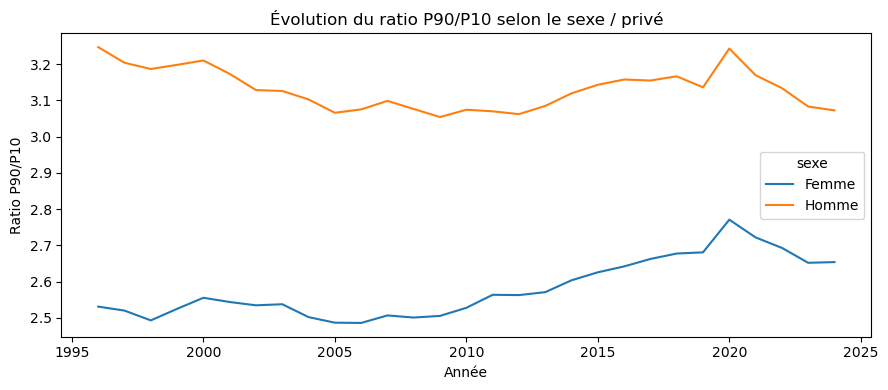

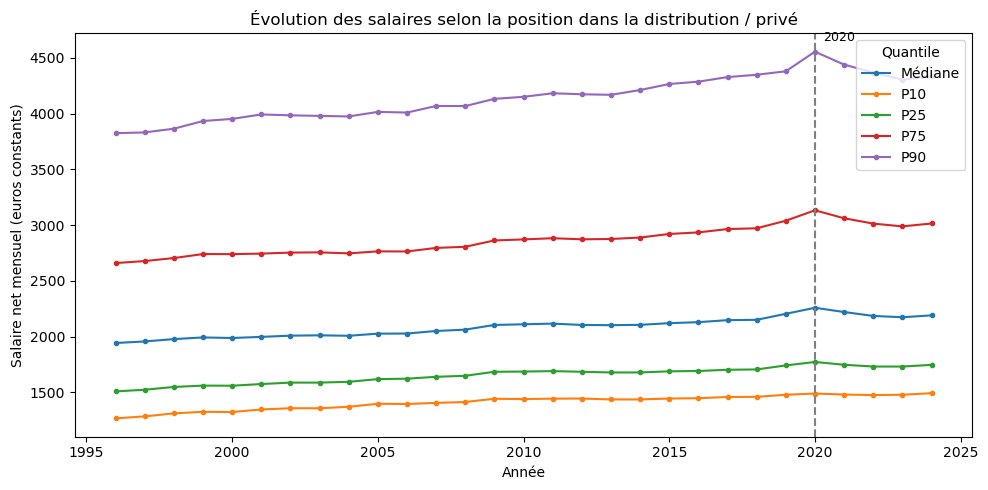

In [ ]:
def calculer_ratio_90_10(df, dimension=None):
    table = extraire_salaire(df, [P10, P90], dimension)
    index = ['annee'] if dimension is None else [dimension, 'annee']
    table = table.pivot(index=index, columns='centile_salaire', values='valeur').dropna()
    table['Ratio P90/P10'] = table[P90] / table[P10]
    return table.reset_index()

ratios_sexe = calculer_ratio_90_10(prive, 'sexe')
pivot_ratios_sexe = ratios_sexe[ratios_sexe['sexe'].isin(['Homme', 'Femme'])].pivot(
    index='annee', columns='sexe', values='Ratio P90/P10'
).dropna()

pivot_ratios_sexe.plot(figsize=(9, 4))
plt.title('Évolution du ratio P90/P10 selon le sexe / privé')
plt.xlabel('Année')
plt.ylabel('Ratio P90/P10')
plt.tight_layout()
plt.show()

# Évolution des salaires selon les quantiles
quantiles_a_tracer = [(P10, 'P10'), (P25, 'P25'), (P50, 'Médiane'), (P75, 'P75'), (P90, 'P90')]

series_quantiles = pd.concat(
    [serie_quantile(prive, q, nom) for q, nom in quantiles_a_tracer],
    ignore_index=True
)

pivot_quantiles = series_quantiles.pivot(
    index='annee', columns='Série', values='Salaire (€ constants)'
).sort_index()

ax = pivot_quantiles.plot(figsize=(10, 5), marker='o', markersize=3)

if 2020 in pivot_quantiles.index:
    ax.axvline(2020, color='gray', linestyle='--')
    ax.annotate('2020', (2020, pivot_quantiles.loc[2020, 'P90']), xytext=(6, 8),
                textcoords='offset points', fontsize=9)

plt.title('Évolution des salaires selon la position dans la distribution / privé')
plt.xlabel('Année')
plt.ylabel('Salaire net mensuel (euros constants)')
plt.legend(title='Quantile')
plt.tight_layout()
plt.show()


## 5. Comparaison des P90/P90 et P10/P10 hommes-femmes

On compare l’évolution des ratios **P90H/ P90F** et **P10H/ P10F**. 

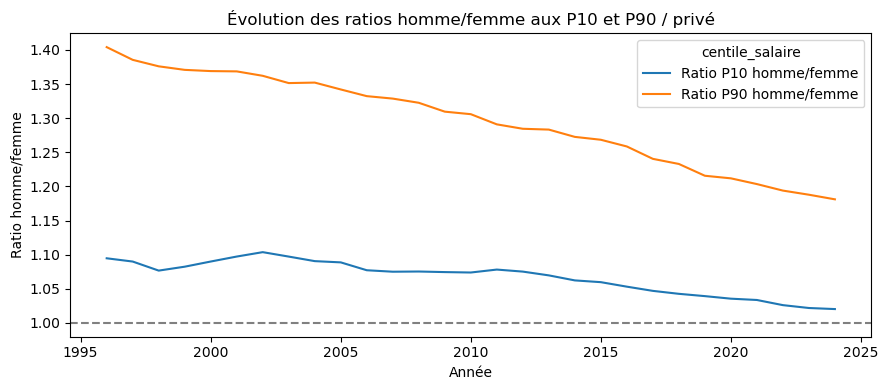

In [ ]:
salaires_p10_p90_sexe = extraire_salaire(prive, [P10, P90], 'sexe')
salaires_p10_p90_pivot = salaires_p10_p90_sexe.pivot(
    index=['annee', 'centile_salaire'], columns='sexe', values='valeur'
).dropna(subset=['Homme', 'Femme'])
salaires_p10_p90_pivot['Ratio Homme/Femme'] = (
    salaires_p10_p90_pivot['Homme'] / salaires_p10_p90_pivot['Femme']
)
ratios_p10_p90_sexe = salaires_p10_p90_pivot['Ratio Homme/Femme'].unstack(
    'centile_salaire'
).rename(columns={P10: 'Ratio P10 homme/femme', P90: 'Ratio P90 homme/femme'})

ratios_p10_p90_sexe.plot(figsize=(9, 4))
plt.axhline(1, color='gray', linestyle='--')
plt.title('Évolution des ratios homme/femme aux P10 et P90 / privé')
plt.xlabel('Année')
plt.ylabel('Ratio homme/femme')
plt.tight_layout()
plt.show()


## 6. Part de la masse salariale

Le fichier privé contient aussi la part de la masse salariale reçue par les 10 %, 1 %, 0,1 % et 0,01 % les mieux rémunérés. 

Sur le long terme, la concentration de la masse salariale en haut de la distribution reste forte mais relativement stable après un recul dans les années 1970 : en 2024, les 10 % les mieux rémunérés captent 27,57 % de la masse salariale et le top 1 % en détient 6,80 % (contre 1,89 % pour le top 0,1 % et 0,56 % pour le top 0,01 %). On observe un léger bond en 2020 durant la crise sanitaire (la part du top 10 % remonte à 29,10 % et celle du top 1 % à 7,20 %), puis un repli. Cela laisse croire à une légère atténuation de la concentration des très hauts salaires sur les toutes dernières années.

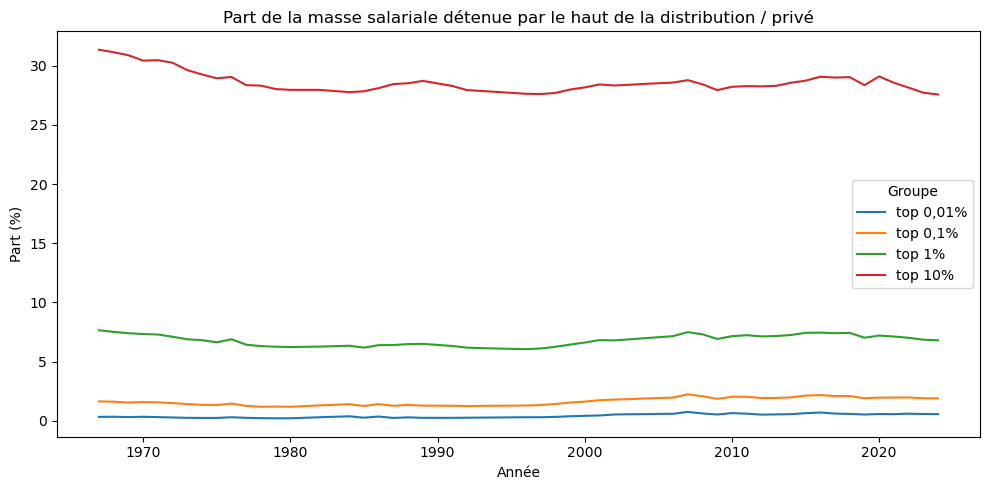

In [ ]:
part_top = garder_ensemble_des_autres_dimensions(prive)
part_top = part_top[
    part_top['indicateur'].str.startswith('Part de la masse salariale perçue par le top ')
    & part_top['centile_salaire'].eq('Ensemble')
].copy()
part_top['Groupe'] = part_top['indicateur'].str.extract(r'(top .+)$', expand=False)
part_top = part_top.pivot(index='annee', columns='Groupe', values='valeur')
part_top.plot(figsize=(10, 5))
plt.title('Part de la masse salariale détenue par le haut de la distribution / privé')
plt.xlabel('Année')
plt.ylabel('Part (%)')
plt.tight_layout()
plt.show()
